# diffsvg: full tutorial

diffsvg finds **differential spatially variable genes**: genes whose expression changes differently with the distance to an anchor in two conditions. This tutorial uses legnini et al.: 17 slides of neural organoid-like cultures, 6 Ctrl and 11 exposed to SHH, 88 genes. The anchor is the SHH+ cells.

1. **Quickstart**: the fastest route from data to a volcano plot, on one model for the whole dataset.
2. **Grid search**: how much the ranking depends on the settings, and which settings to keep.
3. **The full model**: those settings, plus the variation between slides.
4. **Clustering**: two ways of grouping the genes by their curves.

Every fit uses the exact posterior (`inference="auto"`), so no sampler runs and the whole notebook takes a few minutes on a laptop.

**A caveat on the anchor.** The anchor is the top 1% of SHH expression over all slides. In Ctrl slides these are a few local cells, in SHH slides SHH is expressed widely, so the distance to the anchor does not measure the same thing in both conditions. Keep this in mind when reading single genes, e.g. HHIP.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
# This has to happen before numpy is imported, so restart the kernel if numpy is already loaded.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
LAYER = "log1p_norm"
TAU = 0.1
timings = {}

/Users/tim.treis/Documents/GitHub/diffsvg-exact/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

`var_by_distance` gives every cell its distance to the closest anchor cell of its own slide, scaled to 0-1 per slide, and collects what the model needs in `adata.obsm["design_matrix"]`. Here, the anchor is the top percentile of SHH expression. Anchor cells themselves have no distance, and `slide1_A2-2` has no anchor cells, so it drops out of the fits.

In [2]:
adata = sc.read_h5ad(os.environ.get("DIFFSVG_DATA", "data/legnini23.h5ad"))

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
design = adata.obsm["design_matrix"]
design.head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


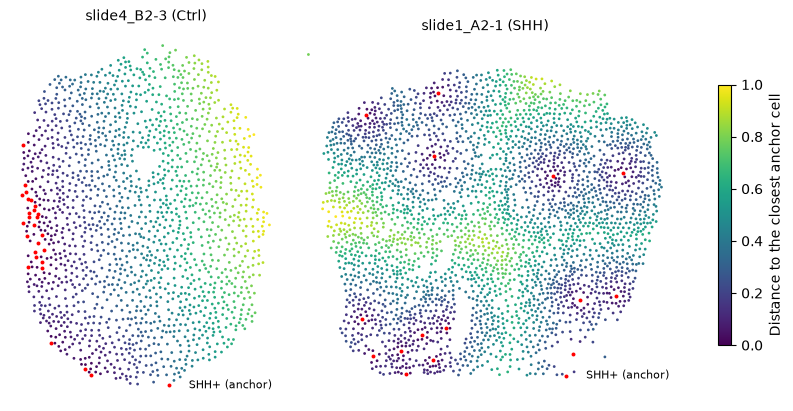

In [3]:
EXAMPLE_SLIDES = ["slide4_B2-3", "slide1_A2-1"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, slide in zip(axes, EXAMPLE_SLIDES, strict=True):
    in_slide = (design["sample"] == slide).to_numpy()
    anchor = in_slide & design["True"].isna().to_numpy()
    others = in_slide & ~anchor
    xy = adata.obsm["spatial"]
    points = ax.scatter(*xy[others].T, c=design["True"].to_numpy()[others], cmap="viridis", vmin=0, vmax=1, s=4, linewidth=0)
    ax.scatter(*xy[anchor].T, color="red", s=8, linewidth=0, label="SHH+ (anchor)")
    ax.set_title(f"{slide} ({design.loc[in_slide, 'condition'].iloc[0]})", fontsize=10)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.colorbar(points, ax=axes, shrink=0.7, label="Distance to the closest anchor cell");

## 1. Quickstart

Three calls and a plot:

* `pp.bin_obs` averages each gene in bins along the distance, per condition. `window_radius=None` makes the bins contiguous, so each cell counts once.
* `tl.fit_model` fits one spline per gene and condition, and tests whether the two curves differ by more than a shift in level (`test="parallel"`). `tau` is the smallest shape difference that counts.
* `pl.plot_volcano` shows the effect (`slope_diff`, how the gap between the curves changes with distance) against the significance.

### Inference

The model is linear with Gaussian noise and normal priors, so `fit_model` computes its posterior exactly (`inference="auto"`): the coefficients are Gaussian given the noise scale, and the noise scale is integrated out numerically. This is the posterior NUTS samples from, without the Monte Carlo error; on these 88 genes both give the same genes at BH < 0.05, the exact fit in under a second.


/var/folders/qg/qgc908995g3fc8qtss2fsbhhxyxxj4/T/ipykernel_64500/3630153356.py:3: UserWarning: Column 'sample' looks like replicates (slides/samples) nested in 'condition' (6+ per condition), but `sample` was not given, so every cell is treated as an independent replicate and slide-to-slide variation counts as a condition effect. Pass `sample='sample'` to model it.
  dvg.pp.bin_obs(adata, anchor="True", condition="condition", layer=LAYER, window_radius=None)


Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models: 100%|██████████| 88/88 [00:00<00:00, 248551.35it/s]

1 s


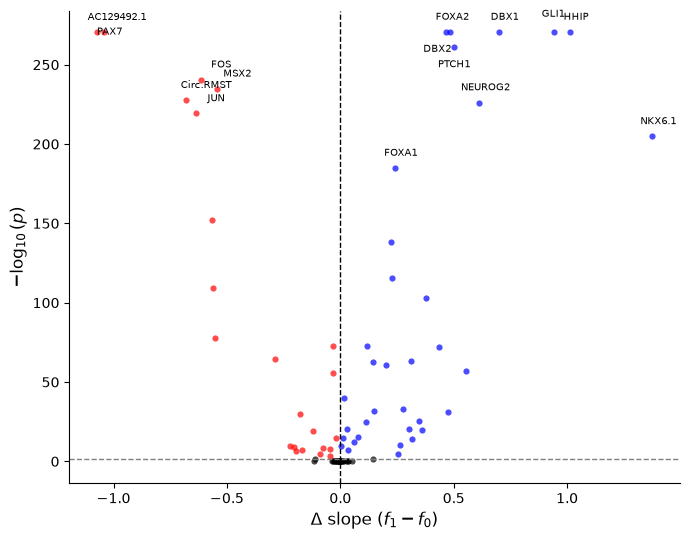

In [4]:
t0 = time.perf_counter()

dvg.pp.bin_obs(adata, anchor="True", condition="condition", layer=LAYER, window_radius=None)
setup = dvg.tl.setup_model(adata)
dvg.tl.fit_model(adata, setup, n_workers=N_WORKERS, test="parallel", tau=TAU)

timings["1. Quickstart"] = time.perf_counter() - t0
print(f"{timings['1. Quickstart']:.0f} s")

quick = adata.varm["dsvg_stats"].copy()
dvg.pl.plot_volcano(quick, n_label=15, figsize=(7, 5.5));

The curves are compared as condition 1 minus condition 0, with the labels in sorted order, so here SHH minus Ctrl. Blue genes have a gap that grows with the distance from the anchor, red genes one that shrinks.

`plot_prediction_curve` shows what is behind a point of the volcano. Bands are posterior-predictive, so they hold the noise of a bin as well as the uncertainty of the curve: judge the difference by the test and the mean curves.

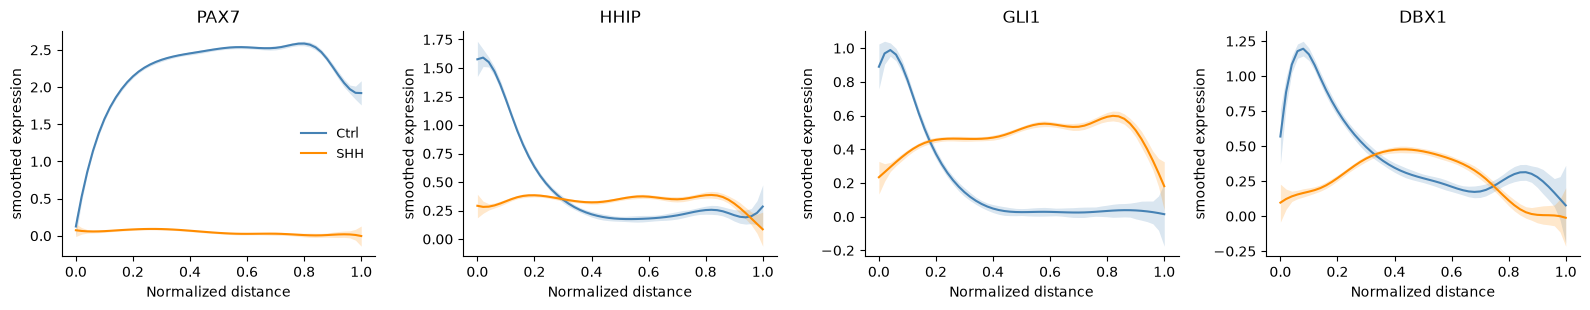

In [5]:
quick_top = list(quick.sort_values(["parallel_pval", "parallel_stat"], ascending=[True, False]).index[:4])
dvg.pl.plot_prediction_curve(adata, gene=quick_top);

**This model is too confident on data with several slides.** It pools the cells of a condition, so a difference between two slides looks like a difference between the conditions, and with 40,000 cells it is significant. On a split of the SHH slides into two groups, where no true difference exists, a model like this flags most of the genes. Use it to look around. Part 3 is the one to report.

## 2. Grid search

The model has settings that nothing in the data fixes directly, chiefly the flexibility of the splines (`n_bsplines`) and the number of bins (`n_bins`). `check_stability` refits the whole panel for every combination and compares the rankings. The fits are exact and therefore deterministic, so any change in the ranking comes from the settings and not from sampling noise.

The runs use the slide model (`sample="sample"`), the same model as part 3. `rank_by="parallel_stat"` ranks by the statistic of the curve test, which unlike the p-value does not saturate at 0 or 1.

**What "optimal" means here.** There is no ground truth, so no setting can be shown to be the most accurate. What can be measured is whether more flexibility still changes the answer. So the baseline is the richest setting, and we keep the *smallest* setting whose ranking agrees closely with it: a Spearman correlation of at least 0.95 and at least 80% of its top 20 genes. The two thresholds are a choice, not a test.

In [6]:
GRID = {"n_bsplines": [6, 10, 14], "n_bins": [25, 50, 100]}
RICHEST = {"n_bsplines": 14, "n_bins": 100}

t0 = time.perf_counter()
stability = dvg.tl.check_stability(
    adata, anchor="True", condition="condition", grid=GRID, baseline=RICHEST, genes=None,
    rank_by="parallel_stat", top_k=20, test="parallel", tau=TAU, sample="sample",
)  # fmt: skip
timings["2. Grid search"] = time.perf_counter() - t0
print(f"{timings['2. Grid search']:.0f} s")


Checking DiffSVG stability:   0%|          | 0/9 [00:00<?, ?it/s]

Checking DiffSVG stability:  11%|█         | 1/9 [00:48<06:24, 48.06s/it]

Checking DiffSVG stability:  22%|██▏       | 2/9 [01:34<05:29, 47.11s/it]

Checking DiffSVG stability:  33%|███▎      | 3/9 [02:22<04:44, 47.34s/it]

Checking DiffSVG stability:  44%|████▍     | 4/9 [03:38<04:54, 58.89s/it]

Checking DiffSVG stability:  56%|█████▌    | 5/9 [04:55<04:20, 65.21s/it]

... (2 outputs left out)

Checking DiffSVG stability:  89%|████████▉ | 8/9 [09:47<01:30, 90.43s/it]

Checking DiffSVG stability: 100%|██████████| 9/9 [11:49<00:00, 100.38s/it]

Checking DiffSVG stability: 100%|██████████| 9/9 [11:49<00:00, 78.86s/it] 

710 s


The heatmap compares every run with every other. Runs on the same branch of the dendrogram rank the genes the same way.

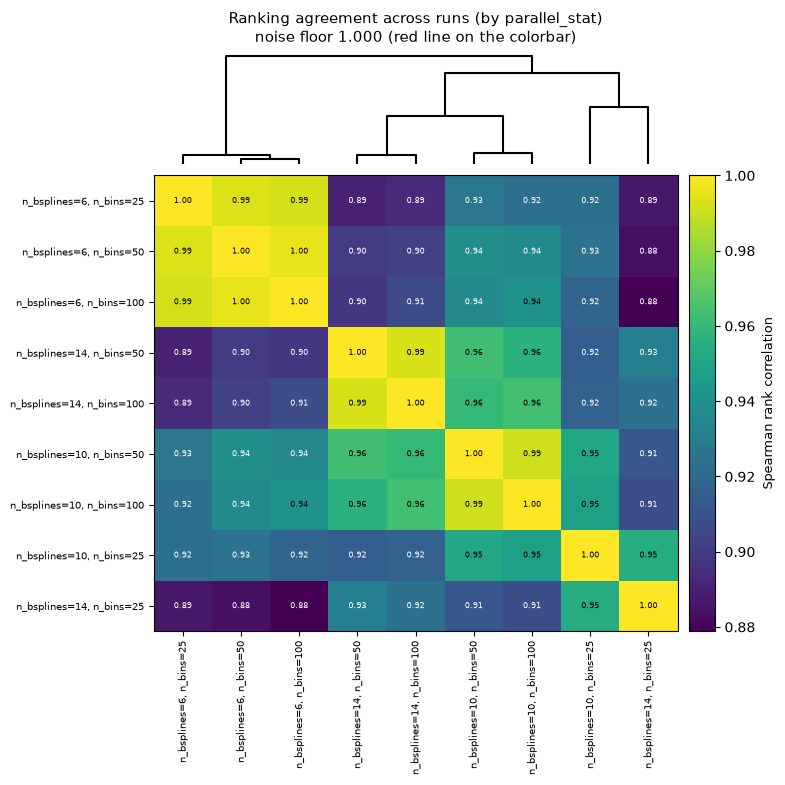

In [7]:
dvg.pl.plot_stability(stability, kind="heatmap", metric="spearman");

The same comparison against the baseline, with one setting changed at a time, shows which setting moves the ranking.

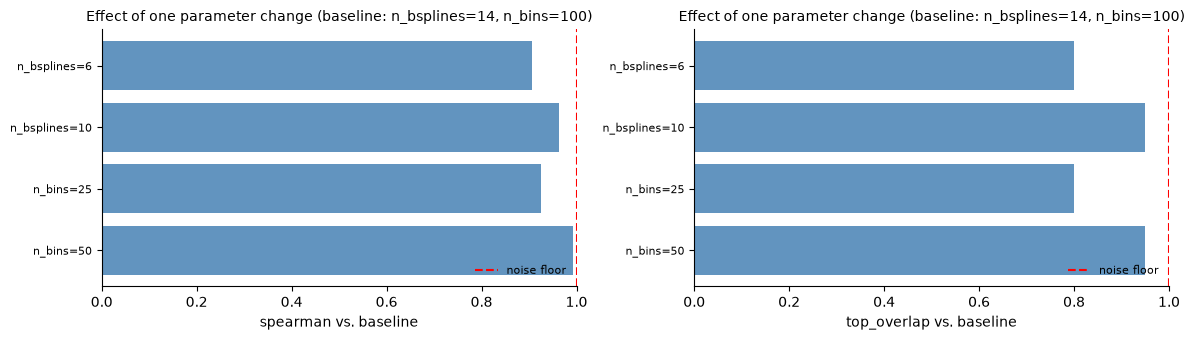

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
dvg.pl.plot_stability(stability, kind="sensitivity", metric="spearman", ax=axes[0])
dvg.pl.plot_stability(stability, kind="sensitivity", metric="top_overlap", ax=axes[1])
fig.tight_layout();

In [9]:
MIN_SPEARMAN, MIN_TOP_OVERLAP = 0.95, 0.8

runs = stability.configs[["n_bsplines", "n_bins"]].astype(int)
runs["spearman"] = stability.similarity.loc[stability.baseline, runs.index]
runs["top_overlap"] = stability.top_overlap.loc[stability.baseline, runs.index]
runs["close to the richest"] = (runs["spearman"] >= MIN_SPEARMAN) & (runs["top_overlap"] >= MIN_TOP_OVERLAP)

best = runs[runs["close to the richest"]].sort_values(["n_bsplines", "n_bins"]).iloc[0]
N_BSPLINES, N_BINS = int(best["n_bsplines"]), int(best["n_bins"])
print(f"Kept: n_bsplines = {N_BSPLINES}, n_bins = {N_BINS}")
runs.sort_values(["n_bsplines", "n_bins"]).round(3)


Kept: n_bsplines = 10, n_bins = 50


,n_bsplines,n_bins,spearman,top_overlap,close to the richest
"n_bsplines=6, n_bins=25",6,25,0.893,0.75,False
"n_bsplines=6, n_bins=50",6,50,0.903,0.75,False
"n_bsplines=6, n_bins=100",6,100,0.907,0.80,False
"n_bsplines=10, n_bins=25",10,25,0.917,0.85,False
"n_bsplines=10, n_bins=50",10,50,0.960,0.95,True
"n_bsplines=10, n_bins=100",10,100,0.963,0.95,True
"n_bsplines=14, n_bins=25",14,25,0.925,0.80,False
"n_bsplines=14, n_bins=50",14,50,0.993,0.95,True
"n_bsplines=14, n_bins=100",14,100,1.000,1.00,True


## 3. The full model

The chosen settings, now with slides: `sample="sample"` adds a random level and a random curve per slide. That is what the over-confidence of the quickstart was missing, because the conditions are now compared against the variation between slides rather than between cells.

* **Slide scales:** the two scales of the slide effects are integrated out numerically for every gene, together with the noise scale, so their uncertainty enters the test.
* **F reference:** the p-value uses `n_slides - 2` denominator degrees of freedom, because the covariance now holds scale estimates from few slides.
* **Bins or cells:** contiguous bins per slide are weighted by their cell counts, so they have the same likelihood as the cells and give nearly the same statistics. For the fit to cells, set `USE_BINNED = False`.


In [10]:
USE_BINNED = True

t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", layer=LAYER, n_bsplines=N_BSPLINES, n_bins=N_BINS,
    window_radius=None, sample="sample",
)  # fmt: skip
dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=USE_BINNED,
    test="parallel", tau=TAU,
)  # fmt: skip
timings["3. Full model"] = time.perf_counter() - t0
print(f"{timings['3. Full model'] / 60:.1f} min")

stats = adata.varm["dsvg_stats"].copy()

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models: 100%|██████████| 88/88 [00:00<00:00, 738197.50it/s]

1.2 min


### Did the integration work?

`exact_edge_mass` is the share of each gene's posterior that sits at the edge of the integration grid. Values near 0 mean the grid covers the posterior.

In [11]:
stats["grid_ok"] = stats["exact_edge_mass"] < 0.05
print(f"{stats['grid_ok'].sum()} of {len(stats)} genes have less than 5% of their posterior at the grid edge")
stats.loc[~stats["grid_ok"], ["exact_edge_mass", "sample_level_sd", "sample_curve_sd", "parallel_pval"]]


88 of 88 genes have less than 5% of their posterior at the grid edge


,exact_edge_mass,sample_level_sd,sample_curve_sd,parallel_pval


### Ranked genes

In [12]:
ranked = stats.sort_values(["parallel_pval", "parallel_stat"], ascending=[True, False])
ranked[
    ["shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high", "parallel_stat", "parallel_pval",
     "parallel_pval_adj", "integral", "sample_level_sd", "sample_curve_sd", "exact_edge_mass"]
].head(20)  # fmt: skip

,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,sample_level_sd,sample_curve_sd,exact_edge_mass
HHIP,1.371689,0.906362,0.629139,1.168256,139.321547,0.000105,0.009276,-0.085680,0.117186,0.273379,7.218398e-26
FOXA2,0.771338,0.388337,0.187082,0.585860,146.314108,0.000295,0.010134,0.009368,0.045839,0.207789,4.229927e-31
GLI1,1.165102,0.832713,0.600304,1.073135,112.669924,0.000453,0.010134,0.278593,0.102868,0.247804,1.298530e-26
PAX7,1.472464,-0.902066,-1.280185,-0.515268,93.612574,0.000461,0.010134,-2.109730,0.221095,0.399361,1.305921e-20
NEUROG2,1.070546,0.368853,0.070095,0.683514,67.481623,0.002785,0.049018,0.635105,0.238080,0.311203,7.742137e-22
MSX2,0.606095,-0.537869,-0.655189,-0.430545,122.033370,0.008328,0.109532,-0.448754,0.155685,0.108150,2.979851e-24
PTCH1,1.220757,0.178939,-0.247673,0.576534,47.241583,0.008713,0.109532,0.144764,0.357766,0.432769,3.695301e-19
DBX2,0.972010,0.630448,0.331244,0.925874,40.969222,0.029169,0.320857,-0.320214,0.171108,0.316234,1.048744e-23
FOXA1,0.385451,0.188005,0.034168,0.328753,83.833867,0.035685,0.348917,-0.017872,0.030516,0.151086,1.805358e-33
JUN,1.165882,-0.649343,-1.060968,-0.243972,30.340262,0.046129,0.379300,-0.285465,0.154718,0.440305,5.761497e-24


### Volcano and p-value histogram

With `tau > 0`, genes whose shape difference is clearly below `tau` get p-values near 1, so the histogram has a second peak there by design.

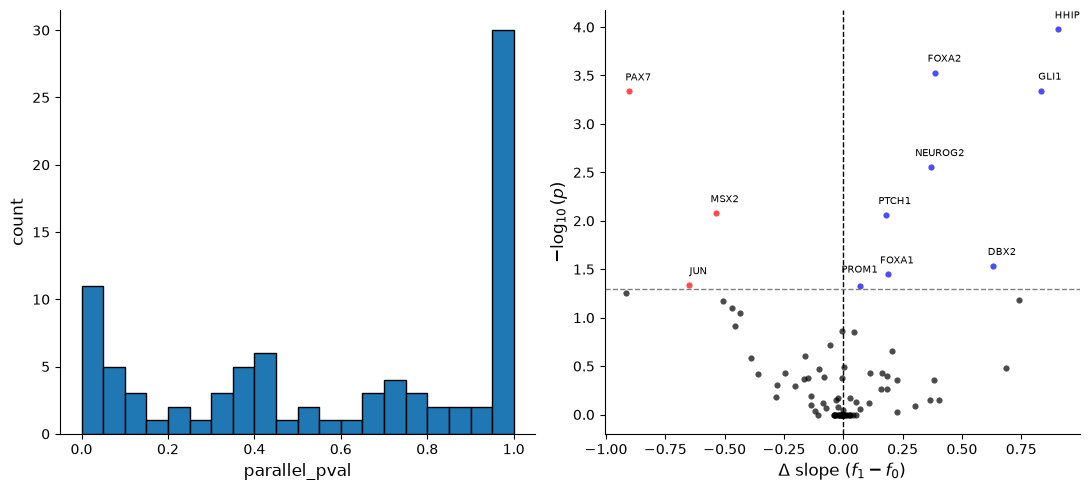

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
dvg.pl.plot_pvalue_histogram(stats, ax=axes[0])
dvg.pl.plot_volcano(stats, ax=axes[1], n_label=15)
fig.tight_layout();

### What modelling the slides changed

The quickstart against the full model. Most genes the quickstart flags are no longer significant once the variation between slides is taken into account.

,Quickstart,Full model
p < 0.05,58,11
BH < 0.05,58,5


Spearman of the statistics: 0.67
Flagged by the full model (BH < 0.05): HHIP, FOXA2, GLI1, PAX7, NEUROG2


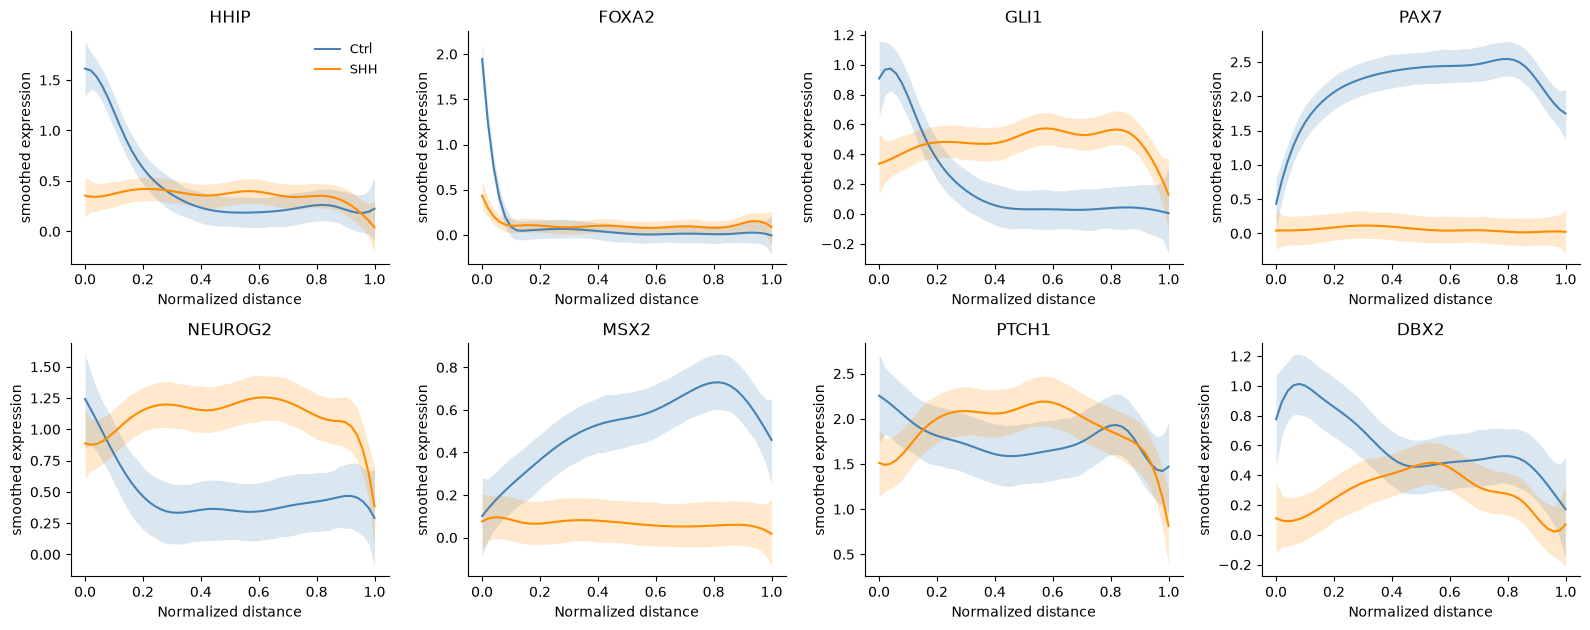

In [14]:
display(
    pd.DataFrame(
        {
            "Quickstart": {"p < 0.05": (quick["parallel_pval"] < 0.05).sum(), "BH < 0.05": (quick["parallel_pval_adj"] < 0.05).sum()},
            "Full model": {"p < 0.05": (stats["parallel_pval"] < 0.05).sum(), "BH < 0.05": (stats["parallel_pval_adj"] < 0.05).sum()},
        }
    )
)
print("Spearman of the statistics:", round(quick["parallel_stat"].corr(stats["parallel_stat"], method="spearman"), 2))

FLAGGED = list(ranked.index[ranked["parallel_pval_adj"] < 0.05])
print("Flagged by the full model (BH < 0.05):", ", ".join(FLAGGED))
dvg.pl.plot_prediction_curve(adata, gene=list(ranked.index[:8]));

## 4. Clustering

`tl.cluster_curves` runs k-means on the posterior means of the spline coefficients, so genes group by the shape of their curves. There are two ways to do this, and they answer different questions:

* **Combined** (`by="average"`): the mean of the two condition curves. Which patterns along the distance exist in this data?
* **Interaction** (`by="interaction"`): the difference between the conditions. In which ways do the conditions differ?

### Choosing `k`

The silhouette (higher is better), for both. It tends to favour small `k`, where a large flat cluster stands against a few strong patterns, so it is a guide and does not settle the choice.

In [15]:
silhouettes = {}
for by in ("average", "interaction"):
    for k in range(2, 9):
        dvg.tl.cluster_curves(adata, by=by, n_clusters=k, key_added="scan")
        silhouettes[by, k] = adata.uns["scan"]["silhouette"]
del adata.var["scan"], adata.uns["scan"]
pd.Series(silhouettes).unstack(0).round(3).rename_axis("k")

,average,interaction
k,,
2,0.427,0.342
3,0.438,0.469
4,0.407,0.329
5,0.430,0.340
6,0.458,0.336
7,0.446,0.350
8,0.448,0.341


In [16]:
N_CLUSTERS = 5


def cluster_table(key):
    """One row per cluster: its size, how many of its genes the test flags, and the genes."""
    labels = adata.var[key].dropna()
    return pd.DataFrame(
        {
            cluster: {
                "n": len(genes),
                "p < 0.05": int((stats.loc[genes, "parallel_pval"] < 0.05).sum()),
                "BH < 0.05": int((stats.loc[genes, "parallel_pval_adj"] < 0.05).sum()),
                "median shape_diff": round(float(stats.loc[genes, "shape_diff"].median()), 2),
                "genes": ", ".join(genes),
            }
            for cluster, genes in ((c, list(labels.index[labels == c])) for c in labels.cat.categories)
        }
    ).T

### Combined: the curve averaged over both conditions

`beta + beta_1 / 2` are the coefficients of the mean of the two condition curves, weighting both conditions equally. Each gene is centred, so its level plays no part.

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,51,1,0,0.09,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,22,4,0,0.48,"AC129492.1, AGO2, Circ.CDR1, CUL3, DBX1, DBX2,..."
2,7,5,4,0.93,"FOXA1, FOXA2, GLI1, HHIP, NEUROG2, NKX6.1, SHH"
3,5,1,1,0.75,"GLI3, IRX3, PAX6, PAX7, PTPRZ1"
4,3,0,0,0.62,"Circ.RMST, STMN2, TUBB3"


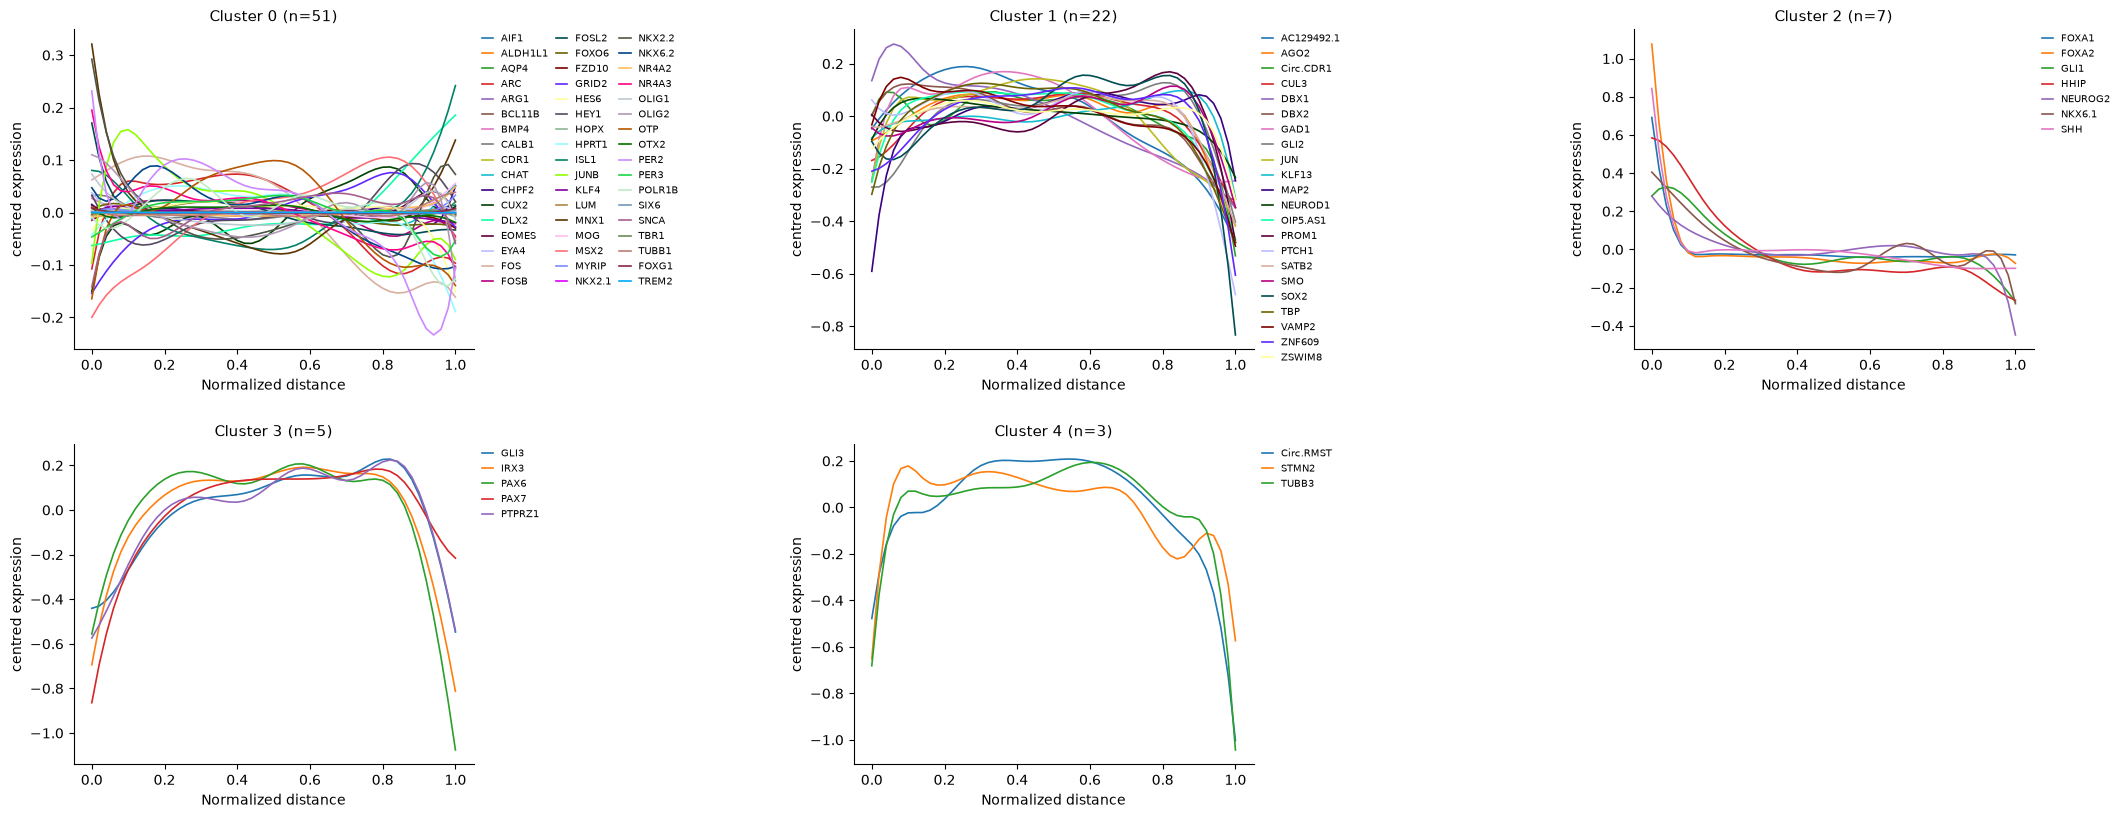

In [17]:
dvg.tl.cluster_curves(adata, by="average", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_average"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_average");

### Interaction: how the conditions differ

`beta_1` is the shape of the difference curve, SHH minus Ctrl. The plot shows those difference curves, since they are what the clustering compared. Amplitude counts here, so genes without a difference collect in a flat cluster.

These are the same coefficients the test is built on, so finding the flagged genes in the patterned clusters describes them and does not confirm them.

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,50,1,0,0.09,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,23,1,0,0.49,"AGO2, CUL3, CUX2, GAD1, GLI2, GLI3, IRX3, KLF1..."
2,8,6,4,1.12,"DBX1, DBX2, FOXA2, GLI1, HHIP, NEUROG2, NKX6.1..."
3,5,2,0,0.75,"AC129492.1, FOS, JUN, JUNB, MSX2"
4,2,1,1,1.26,"Circ.RMST, PAX7"


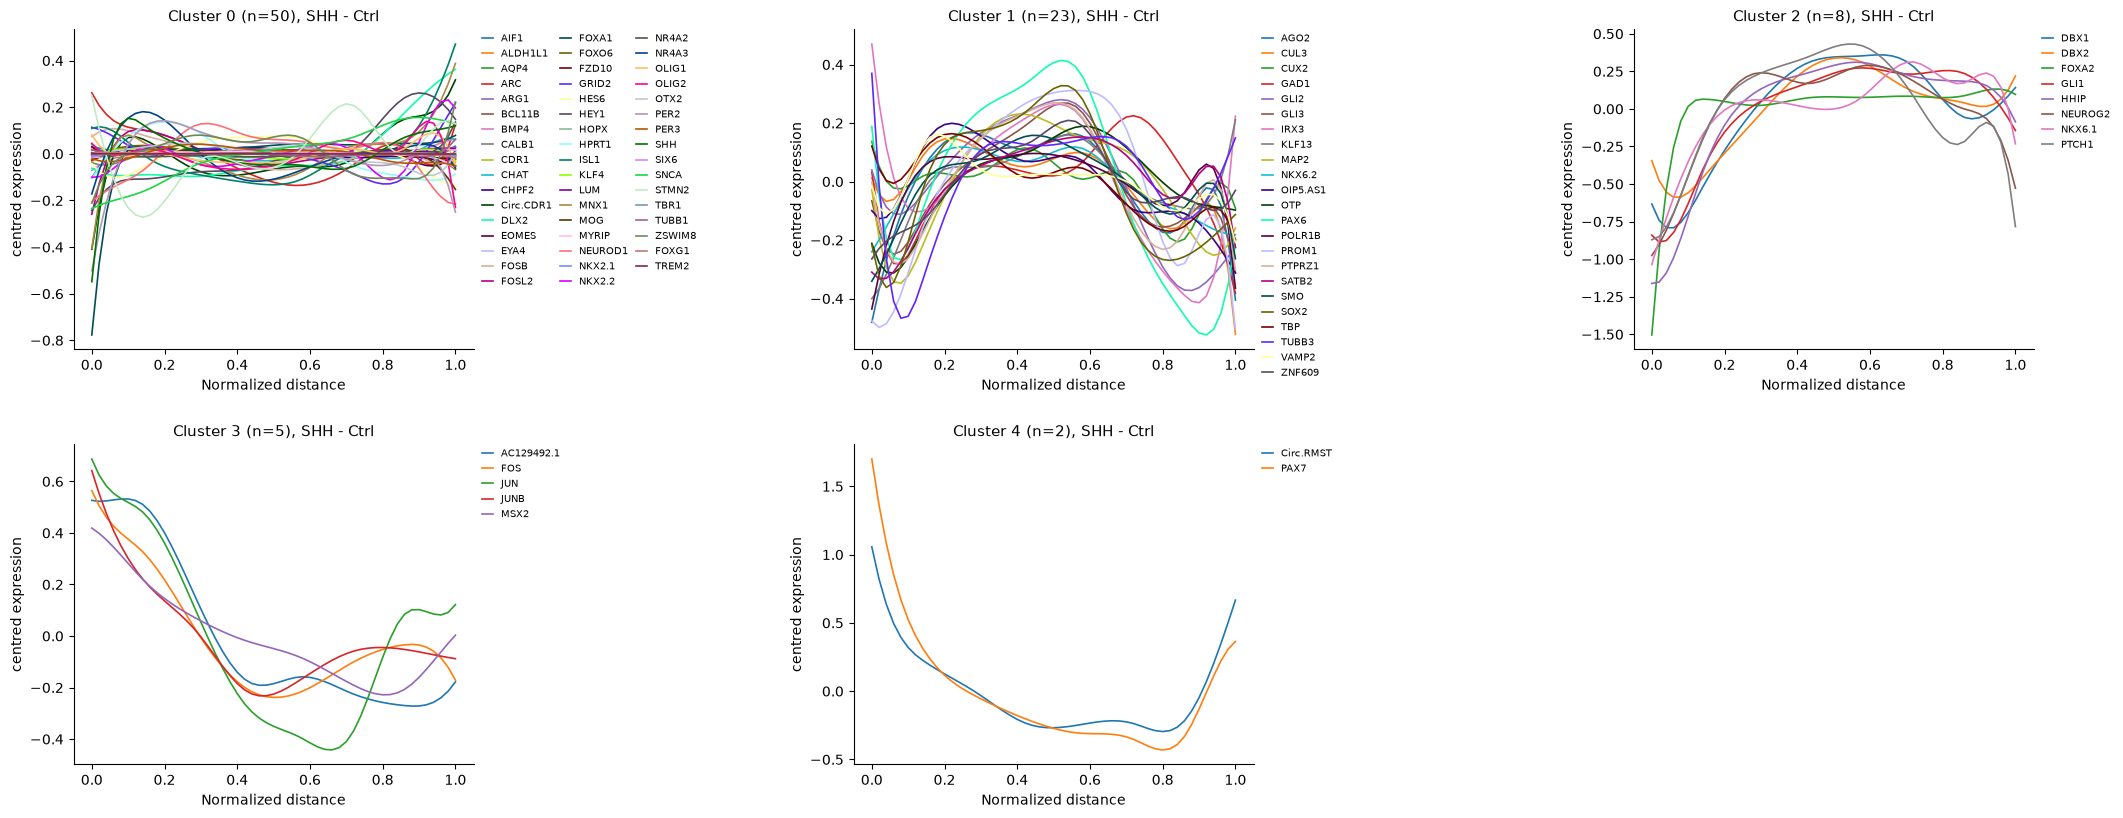

In [18]:
dvg.tl.cluster_curves(adata, by="interaction", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_interaction"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction");

`curves="conditions"` draws the same clusters split by condition: one row per cluster, Ctrl left, SHH right, in a shared y-range and with the same gene colours. Each gene is centred over both conditions together, so the gap between them stays visible. Here, the clusters that hold flagged genes:

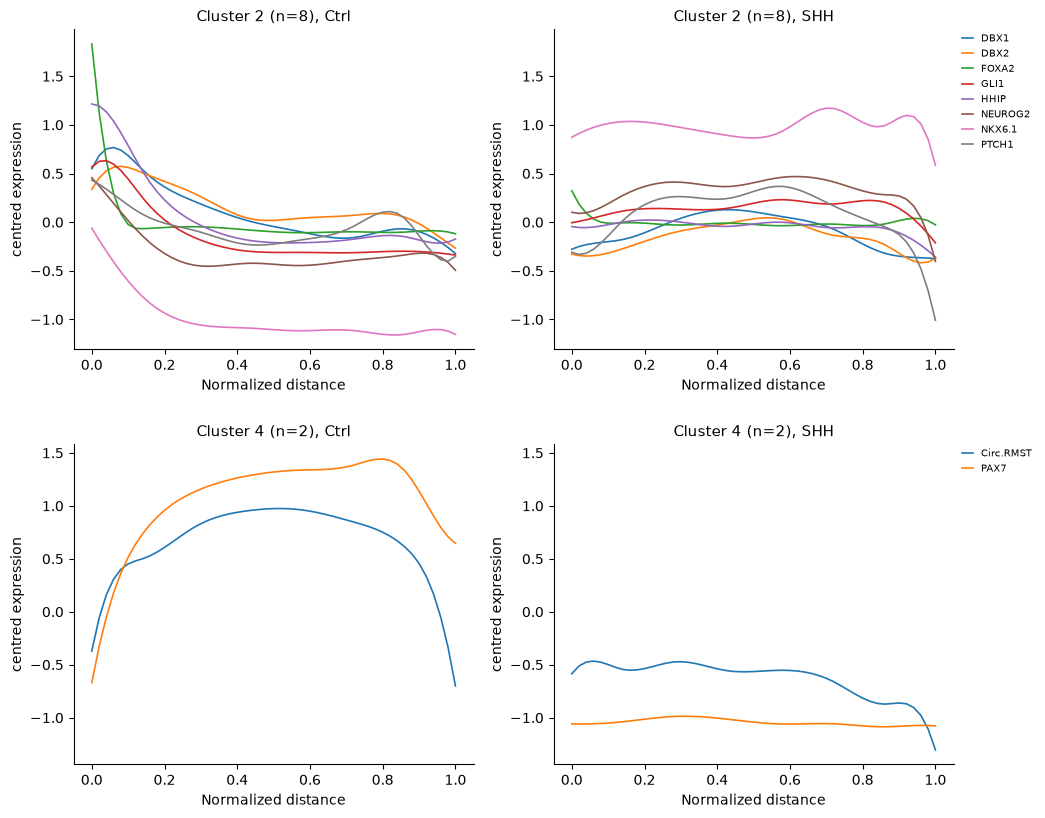

In [19]:
labels = adata.var["dsvg_cluster_interaction"]
with_flagged = sorted(set(labels[FLAGGED])) or None
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction", curves="conditions", clusters=with_flagged);

## Runtime

In [20]:
pd.Series(timings, name="seconds").round(0).to_frame()

,seconds
1. Quickstart,1.0
2. Grid search,710.0
3. Full model,73.0
